In [1]:
import sys
print(sys.executable)

/Users/mateov1996/Desktop/Maestría Ciencia de datos /CIENCIA DE DATOS /PSET2/pset_3/.venv/bin/python


In [2]:
import sys; sys.path.append("..")
from src.datos import cargar_obt, metadatos_datos

df = cargar_obt()
print(df.shape)
print(df["merma_alta"].value_counts())
metadatos_datos(df)

(221, 40)
merma_alta
1    149
0     72
Name: count, dtype: int64


{'tabla_origen': 'CERVECERIA_DB.OBT.OBT_MERMA_LOTES',
 'fecha_corte': '2026-10-27',
 'hash_dataset': '18264c4749f7569c',
 'n_filas': 221}

In [3]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats
from pathlib import Path

FIGS = Path("../docs/figs"); FIGS.mkdir(parents=True, exist_ok=True)
sns.set_theme(style="whitegrid")

# Columnas que solo se conocen DESPUÉS de cerrar el lote -> fuga de datos (no son features)
FUGA = ["cantidad_completada", "merma_litros", "merma_ajustada", "fecha_cierre", "dias_proceso"] \
       + [c for c in df.columns if c.startswith("cierre_")]
IDS = ["numero_documento", "lote"]
TARGET_CONT, TARGET = "merma_pct", "merma_alta"
print("Columnas con fuga:", FUGA)

Matplotlib is building the font cache; this may take a moment.


Columnas con fuga: ['cantidad_completada', 'merma_litros', 'merma_ajustada', 'fecha_cierre', 'dias_proceso', 'cierre_anio', 'cierre_mes', 'cierre_nombre_mes', 'cierre_trimestre', 'cierre_semana_anio', 'cierre_dia_semana', 'cierre_es_fin_de_semana']


In [4]:
print(df.shape)
resumen = pd.DataFrame({
    "tipo": df.dtypes.astype(str),
    "faltantes": df.isna().sum(),
    "pct_faltantes": (df.isna().mean() * 100).round(1),
    "valores_unicos": df.nunique(),
}).sort_values("pct_faltantes", ascending=False)
resumen

(221, 40)


,tipo,faltantes,pct_faltantes,valores_unicos
micro_litros_levadura,float64,190,86.0,30
micro_celulas_viables_m_ml,float64,188,85.1,32
micro_decision,object,186,84.2,3
micro_viabilidad_pct,float64,186,84.2,34
micro_origen_coincide,object,186,84.2,2
levadura_origen,object,39,17.6,15
generacion_levadura,float64,31,14.0,6
levadura_nueva,object,31,14.0,2
generacion_con_conflicto,object,26,11.8,2
lote,object,26,11.8,183


In [5]:
num = df.select_dtypes("number").drop(columns=IDS, errors="ignore")
display(num.describe().T.round(2))
display(df.select_dtypes(["object", "bool"]).describe().T)

,count,mean,std,min,25%,50%,75%,max
generacion_levadura,190.0,1.71,1.28,0.00,1.00,2.00,2.00,5.00
micro_viabilidad_pct,35.0,87.45,16.47,9.59,88.10,92.42,94.96,98.49
micro_celulas_viables_m_ml,33.0,1026.73,409.83,28.00,787.00,1046.00,1236.00,1772.00
micro_litros_levadura,31.0,118.08,43.80,26.33,89.68,114.99,149.24,203.00
cantidad_planificada,221.0,5008.62,2063.88,1550.00,3510.00,5265.00,7020.00,7020.00
cantidad_completada,221.0,4651.71,1953.71,1075.00,3200.00,4725.00,6550.00,7020.00
n_cocciones,221.0,2.85,1.17,0.90,2.00,3.00,4.00,4.00
dias_proceso,221.0,16.65,4.18,8.00,14.00,16.00,18.00,30.00
merma_litros,221.0,356.90,264.82,0.00,155.00,310.00,520.00,1070.00
merma_pct,221.0,7.48,5.09,0.00,3.13,6.70,10.73,30.65


,count,unique,top,freq
estilo,221,9,American Lager,156
lote,195,183,2004202610,2
levadura_nueva,190,2,False,156
levadura_origen,182,15,FV14,23
con_microscopio,221,2,False,171
micro_decision,35,3,Reutilizar,29
sin_generacion,221,2,False,190
generacion_con_conflicto,195,2,False,190
merma_ajustada,221,2,False,219
micro_origen_coincide,35,2,True,19


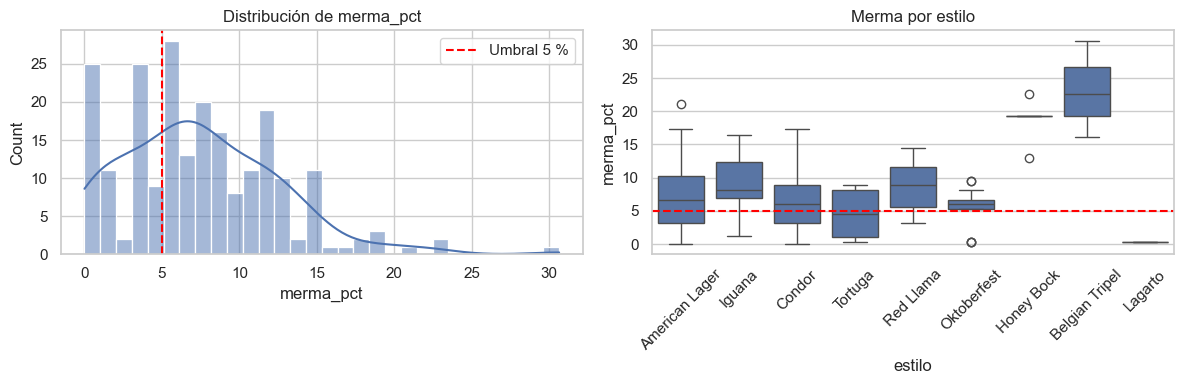

Asimetría: 0.85 | Curtosis: 1.51


In [6]:
fig, ax = plt.subplots(1, 2, figsize=(12, 4))
sns.histplot(df[TARGET_CONT], bins=30, kde=True, ax=ax[0])
ax[0].axvline(5, color="red", ls="--", label="Umbral 5 %"); ax[0].legend()
ax[0].set_title("Distribución de merma_pct")
sns.boxplot(data=df, x="estilo", y=TARGET_CONT, ax=ax[1])
ax[1].axhline(5, color="red", ls="--"); ax[1].tick_params(axis="x", rotation=45)
ax[1].set_title("Merma por estilo")
plt.tight_layout(); plt.savefig(FIGS / "01_target.png", dpi=150); plt.show()

print(f"Asimetría: {df[TARGET_CONT].skew():.2f} | Curtosis: {df[TARGET_CONT].kurt():.2f}")

In [7]:
balance = df[TARGET].value_counts().rename({1: "alta (>5%)", 0: "normal"})
print(balance, "\n", (balance / len(df) * 100).round(1))
display(pd.crosstab(df["estilo"], df[TARGET], margins=True))
display(pd.crosstab(df["coccion_mes"], df[TARGET], normalize="index").round(2))

merma_alta
alta (>5%)    149
normal         72
Name: count, dtype: int64 
 merma_alta
alta (>5%)    67.4
normal        32.6
Name: count, dtype: float64


merma_alta,0,1,All
estilo,,,
American Lager,56,100,156
Belgian Tripel,0,3,3
Condor,4,7,11
Honey Bock,0,5,5
Iguana,2,12,14
Lagarto,1,0,1
Oktoberfest,3,10,13
Red Llama,3,9,12
Tortuga,3,3,6


merma_alta,0,1
coccion_mes,,
1,0.67,0.33
2,0.46,0.54
3,0.38,0.62
4,0.22,0.78
5,0.34,0.66
6,0.28,0.72
7,0.37,0.63
8,0.28,0.72
9,0.23,0.77


,variable,outliers_IQR,outliers_Z>=3,n
0,micro_viabilidad_pct,5,1,35
1,micro_celulas_viables_m_ml,1,0,33
2,micro_litros_levadura,0,0,31
3,merma_pct,3,1,221
4,coccion_semana_anio,0,0,221


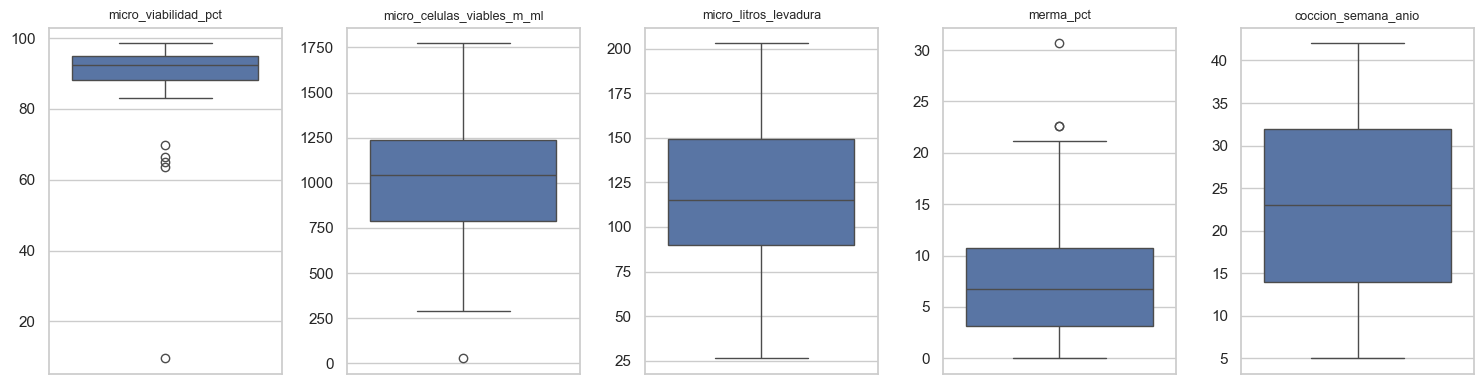

In [8]:
cols_out = [c for c in num.columns if c not in FUGA and num[c].nunique() > 10]
filas = []
for c in cols_out:
    x = df[c].dropna()
    q1, q3 = x.quantile([.25, .75]); iqr = q3 - q1
    n_iqr = ((x < q1 - 1.5 * iqr) | (x > q3 + 1.5 * iqr)).sum()
    n_z = (np.abs(stats.zscore(x)) >= 3).sum()
    filas.append({"variable": c, "outliers_IQR": n_iqr, "outliers_Z>=3": n_z, "n": len(x)})
display(pd.DataFrame(filas))

fig, axes = plt.subplots(1, len(cols_out), figsize=(3 * len(cols_out), 4))
for a, c in zip(np.atleast_1d(axes), cols_out):
    sns.boxplot(y=df[c], ax=a); a.set_title(c, fontsize=9); a.set_ylabel("")
plt.tight_layout(); plt.savefig(FIGS / "02_outliers.png", dpi=150); plt.show()

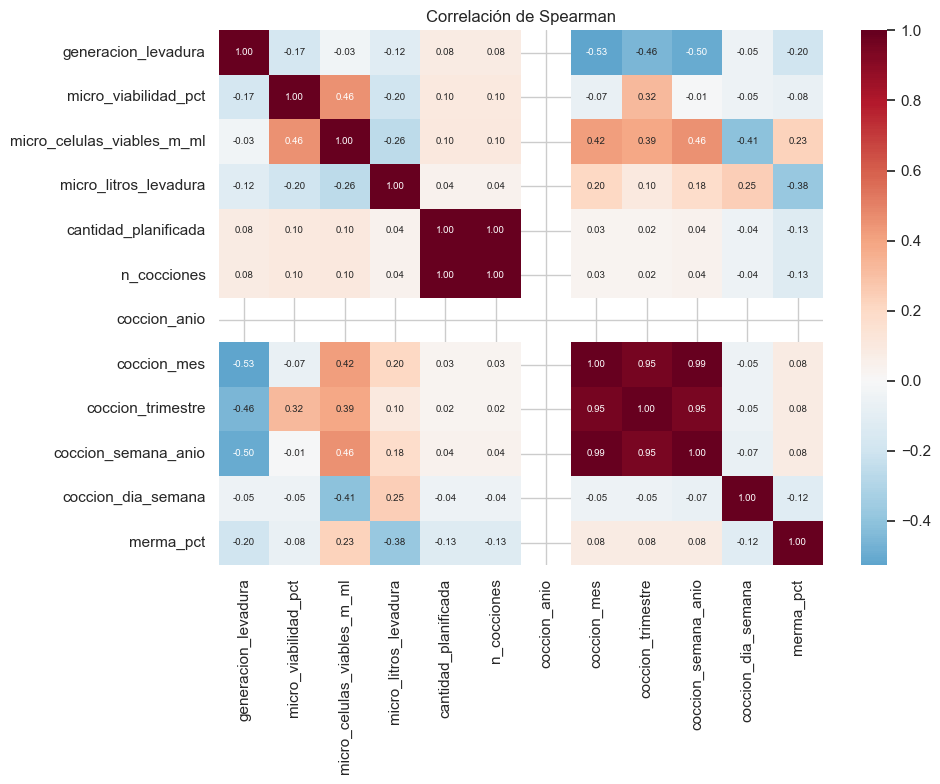

micro_litros_levadura        -0.381
micro_celulas_viables_m_ml    0.228
generacion_levadura          -0.203
cantidad_planificada         -0.128
n_cocciones                  -0.128
coccion_dia_semana           -0.119
coccion_trimestre             0.083
coccion_semana_anio           0.079
coccion_mes                   0.079
micro_viabilidad_pct         -0.076
coccion_anio                    NaN
Name: merma_pct, dtype: float64

In [9]:
cand = [c for c in num.columns if c not in FUGA + [TARGET_CONT, TARGET]]
corr = df[cand + [TARGET_CONT]].corr(method="spearman")
plt.figure(figsize=(10, 8))
sns.heatmap(corr, annot=True, fmt=".2f", cmap="RdBu_r", center=0, annot_kws={"size": 7})
plt.title("Correlación de Spearman"); plt.tight_layout()
plt.savefig(FIGS / "03_correlacion.png", dpi=150); plt.show()

corr[TARGET_CONT].drop(TARGET_CONT).sort_values(key=abs, ascending=False).round(3)

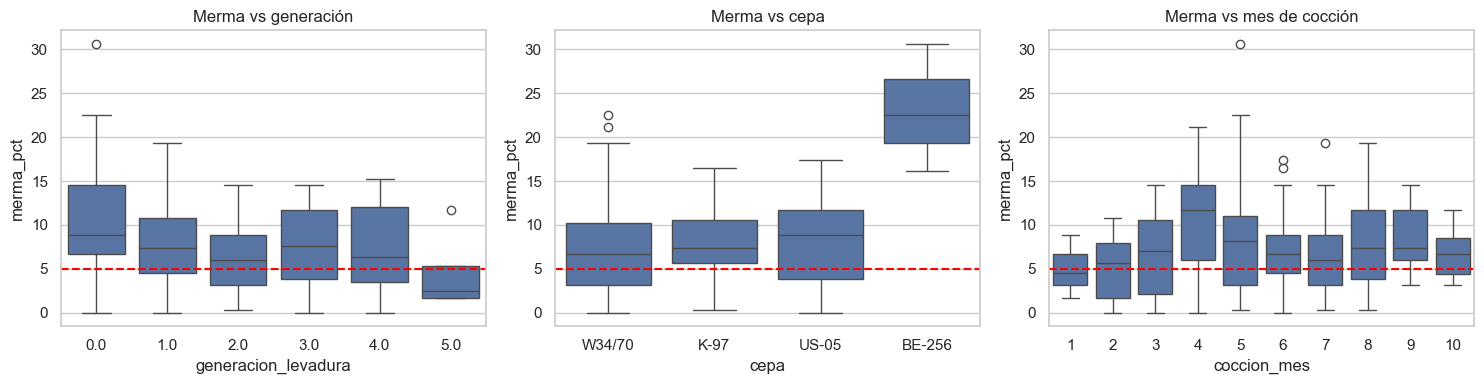

In [10]:
fig, ax = plt.subplots(1, 3, figsize=(15, 4))
sns.boxplot(data=df, x="generacion_levadura", y=TARGET_CONT, ax=ax[0]); ax[0].set_title("Merma vs generación")
sns.boxplot(data=df, x="cepa", y=TARGET_CONT, ax=ax[1]); ax[1].set_title("Merma vs cepa")
sns.boxplot(data=df, x="coccion_mes", y=TARGET_CONT, ax=ax[2]); ax[2].set_title("Merma vs mes de cocción")
for a in ax: a.axhline(5, color="red", ls="--")
plt.tight_layout(); plt.savefig(FIGS / "04_target_vs_proceso.png", dpi=150); plt.show()

#Hallazgos
